# Opsi C v3.4: Bobot Demografi pada SVD dan NMF (MovieLens 1M)

**Tugas Akhir:** Analisis Bias Demografis pada SVD dan NMF dalam Sistem Rekomendasi Menggunakan Pendekatan Extreme Value Theory
**Penulis:** Arkhan Falih Fahrie Puspita (103052330051), S1 Sains Data, Telkom University

Notebook ini menjalankan desain yang dikunci pada **Protokol Analisis Opsi C v3**:

| Komponen | Isi |
|---|---|
| Representasi pengguna | fitur kolaboratif + pseudo-item gender, usia, dan kelompok pekerjaan, bobot alpha |
| Kelompok pekerjaan | 21 kategori MovieLens menjadi 5 kelompok: ISCO-08 skill level (ILO), status aktivitas menurut resolusi ICLS (ILO), ICSE-18 untuk self-employed |
| Pengguna baru | 8 kategori input: Default dan semua kombinasi gender, usia, pekerjaan |
| Grid utama | k {10, 20, 50, 100, 200} x alpha {0, 1, 2, 4, 8} x 5 fold x {SVD, NMF}, jalur warm dan cold |
| Validasi | 5-fold: rating per pengguna dibagi ke 5 fold; pengguna dipartisi ke 5 fold cold-start (stratified gender x usia) |
| Tuning | per model x k, alpha = 0, data validasi, kriteria MAE saja |
| Ablation | encoding hanya-anggota (nilai 5 dan nilai rata-rata pengguna) pada warm dan cold, input tanpa pekerjaan (warm) |
| Pembanding | prediktor BaselineOnly per fold (gap di atas pola rating kelompok) |
| EVT | Pickands (urutan menurun, aturan ties) dengan Moment sebagai pembanding, Top-100, bootstrap B = 999, presisi (MDE) |
| Keputusan | bootstrap berpasangan B = 9999, Holm per keluarga (metrik MAE dan EVT dipisah), mayoritas 4 dari 5 fold, non-inferioritas 10% untuk bobot aman |

## Cara menjalankan bertahap

Ubah variabel `STAGE` pada sel berikut, lalu **Run All**. Setiap sel eksperimen disimpan di `outputs/cache_v3.3/`, sehingga tahap yang sudah selesai tidak diulang.

| STAGE | Isi | Estimasi Kaggle CPU |
|---|---|---|
| `"tuning"` | tuning hyperparameter (grid diperluas, diagnostik k = 300) | 2 sampai 3,5 jam |
| `"control"` | kontrol reprodusibilitas baseline | 2 menit |
| `"baseline"` | prediktor BaselineOnly per fold | 5 menit |
| `"k50"` | grid k = 50 | sekitar 1 sampai 1,5 jam |
| `"k10_20"` | grid k = 10 dan 20 | sekitar 1,5 sampai 2 jam |
| `"k100"` | grid k = 100 | sekitar 1,5 sampai 2,5 jam |
| `"k200"` | grid k = 200 | sekitar 2,5 sampai 4 jam |
| `"ablation"` | encoding hanya-anggota (warm + cold), input tanpa pekerjaan | sekitar 2 sampai 3,5 jam |
| `"all"` | semua tahap di atas berurutan | sekitar 12 sampai 18 jam (laptop) |
| `"analysis"` | hanya analisis dari cache yang ada | kurang dari 15 menit |

Cache v3.3 disimpan di `outputs/cache_v3.3/` (berbeda dari versi sebelumnya); nama berkas sel memuat sidik hyperparameter. Kolom `seed` pada JSON berarti indeks fold (0 sampai 4). Perubahan v3.3: bootstrap B = 9999 (resolusi p cukup untuk Holm), keluarga uji EVT dipisah, Hill dikeluarkan sebagai pembanding, presisi EVT (MDE), uji pengguna baru berpasangan dan uji profil vs Default, ablation encoding pada pengguna baru, pembanding BaselineOnly, H2 deskriptif, k = 200 di grid utama, grid tuning diperluas, ablation NMF dengan bias dihapus, penanda divergensi.

**v3.4 (analisis saja, cache tetap `cache_v3.3`):** inferensi gabungan lintas fold (BBC-CV) sebagai inferensi utama dengan putusan per fold sebagai uji stabilitas, gap relatif (gap / MAE), diagnostik keandalan EVT (kedalaman sama, plateau, saturasi), dan ketahanan tuning. Untuk memperbarui hasil cukup `STAGE = "analysis"`.

Bagian analisis (Bagian 5 dan seterusnya) selalu dijalankan pada akhir notebook dengan cache yang tersedia, lalu menulis `outputs/hasil_running_opsiC_v3.json`.

## 0. Persiapan

In [1]:
# Pilihan: "tuning" | "control" | "baseline" | "k50" | "k10_20" | "k100" | "k200" | "ablation"
# | "all" | "analysis", atau daftar tahap. Lokal: "all". Kaggle (3 sesi): lihat SETUP_KAGGLE.md.
STAGE = "all"
QUICK_MODE = False   # True hanya untuk menguji alur (grid kecil); hasilnya tidak untuk dilaporkan

import os, sys, json, time
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
from IPython.display import display, Image, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

from src import config as C
if QUICK_MODE:
    C.apply_quick_mode(True)
C.ensure_dirs()
from src import data as D, eda, experiment as X, tuning as T, analysis as A, plots as PL, report as RP
from src.recorder import RunRecorder
from src.utils import to_py

rec = RunRecorder()
print("Folder proyek :", ROOT)
print("Data          :", C.DATA_DIR)
print("Cache         :", C.CACHE_DIR, "| sel tersimpan:", len(list(C.CACHE_DIR.glob('*.pkl'))))
print("Grid          : k", C.KS, "| alpha", C.ALPHAS, "| fold", C.SEEDS, "| quick", C.QUICK_MODE)

Folder proyek : d:\Falih\TA\OpsiC-v3
Data          : D:\Falih\TA\OpsiC-v3\data\ml-1m
Cache         : D:\Falih\TA\OpsiC-v3\outputs\cache_v3.3 | sel tersimpan: 705
Grid          : k [10, 20, 50, 100, 200] | alpha [0, 1, 2, 4, 8] | fold [0, 1, 2, 3, 4] | quick False


## 1. Import dataset dan info dataset

In [2]:
with rec.stage("import_dataset"):
    ratings, users, movies = D.load_movielens()
    merged, quality = D.merge_all(ratings, users, movies)
    info = D.dataset_info(ratings, users, movies)
rec.set("dataset", {"info": info, "quality": quality})
display(pd.Series({k: v for k, v in info.items() if not isinstance(v, dict)}).to_frame("nilai"))
display(pd.DataFrame(quality["missing_per_column"], index=["nilai hilang"]))

,nilai
n_users,6.040000e+03
n_movies_rated,3.706000e+03
n_movies_catalog,3.883000e+03
n_ratings,1.000209e+06
sparsity,9.553164e-01
ratings_per_user_median,9.600000e+01
ratings_per_user_mean,1.655975e+02
rating_mean,3.581564e+00


,userId,movieId,rating,timestamp,gender,age,occupation,zip,age_group,occupation_label,occ_group,title,genres
nilai hilang,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. EDA singkat

Ringkasan Subbab 3.3: ketimpangan jumlah pengguna dan rating per kelompok, perbedaan rata-rata rating antar kelompok (Kruskal-Wallis dengan ukuran efek), dan konsentrasi popularitas film. Ketimpangan jumlah data adalah konteks utama untuk membaca disparitas MAE.

In [3]:
with rec.stage("eda"):
    E = eda.run_eda(ratings, users, movies)
rec.set("eda", E)
dd = E["demographic_distribution"]
for attr in ["gender", "age_group", "occ_group"]:
    v = dd[attr]
    print(attr, "| rasio terbesar/terkecil:", round(v.get("imbalance_ratio", float("nan")), 2))
rb = E["rating_by_group"]
for attr in ["gender", "age_group", "occ_group"]:
    kw = rb[attr]
    print(f"Kruskal-Wallis {attr}: p = {kw.get('kruskal_p'):.3g}, epsilon^2 = {kw.get('epsilon_squared'):.4f}")
ip = E["item_popularity"]
print("Gini popularitas:", round(ip.get("gini"), 3), "| porsi rating 20% film teratas:", round(ip.get("share_head"), 3))

gender | rasio terbesar/terkecil: 2.53
age_group | rasio terbesar/terkecil: 9.44
occ_group | rasio terbesar/terkecil: 10.31
Kruskal-Wallis gender: p = 5.82e-94, epsilon^2 = 0.0004
Kruskal-Wallis age_group: p = 0, epsilon^2 = 0.0033
Kruskal-Wallis occ_group: p = 1.11e-84, epsilon^2 = 0.0004
Gini popularitas: 0.634 | porsi rating 20% film teratas: 0.652


## 3. Pembagian data 5-fold dan kelompok pekerjaan

Rating setiap pengguna dibagi rata ke 5 fold, sehingga setiap fold berproporsi 80:20 per pengguna dan setiap rating diuji tepat sekali. Pengguna juga dipartisi ke 5 fold (stratified gender x usia) untuk jalur cold-start, sehingga setiap pengguna menjadi pengguna baru tepat sekali. Tabel pertama menampilkan pemetaan 21 kategori pekerjaan ke 5 kelompok beserta landasannya; tabel kedua ukuran setiap fold dan selisih proporsi kelompok terbesar antara train dan test.

In [4]:
with rec.stage("preprocessing"):
    prep = {}
    for s in C.SEEDS:
        sp = D.FoldSplit(ratings, users, s)
        prep[s] = {**sp.summary(), **D.split_summary(sp.train_df, sp.test_df, users)}
rec.set("preprocessing", prep)
display(pd.DataFrame([{"pekerjaan": k, "kelompok": v, "pengguna": int((users.occupation_label == k).sum())}
                      for k, v in C.OCC_GROUP.items()]).sort_values(["kelompok", "pengguna"], ascending=[True, False]))
display(pd.DataFrame([{"kelompok": g, "pengguna": int((users.occ_group == g).sum()), "landasan": C.OCC_GROUP_BASIS[g]}
                      for g in C.OCC_GROUP_ORDER]))
display(pd.DataFrame(prep).T)
from src.features import preview_rows
sp42 = D.FoldSplit(ratings, users, 0)
uid = int(sp42.train_df.userId.iloc[0])
for enc in C.ENCODINGS:
    print(f"\nContoh pseudo-rating pengguna {uid}, alpha = 1, encoding {enc}: {C.ENCODINGS[enc]}")
    display(preview_rows(users, sp42.train_df, uid, 1, enc))

,pekerjaan,kelompok,pengguna
9,sales/marketing,Keahlian menengah,302
10,clerical/admin,Keahlian menengah,173
11,customer service,Keahlian menengah,112
12,tradesman/craftsman,Keahlian menengah,70
13,farmer,Keahlian menengah,17
0,executive/managerial,Keahlian tinggi,679
1,academic/educator,Keahlian tinggi,528
2,technician/engineer,Keahlian tinggi,502
3,programmer,Keahlian tinggi,388
4,writer,Keahlian tinggi,281


,kelompok,pengguna,landasan
0,Keahlian tinggi,3154,ISCO-08 kelompok utama 1-3 (skill level 3-4)
1,Keahlian menengah,674,ISCO-08 kelompok utama 4-8 (skill level 2); sa...
2,Pelajar/mahasiswa,954,ILO ICLS: status aktivitas utama 'studies'
3,Tidak bekerja,306,ILO ICLS: not in employment (menganggur + di l...
4,Tidak terklasifikasi,952,other: tanpa informasi; self-employed: status ...


,fold,n_train,n_test,n_cold_users,n_cold_ratings,n_warm_ratings,max_abs_share_diff_train_vs_test
0,0,797758,202451,1213,215007,785202,"{'gender': 0.0006465521340515701, 'age_group':..."
1,1,798961,201248,1211,195391,804818,"{'gender': 0.00025383973408199534, 'age_group'..."
2,2,800193,200016,1210,187913,812296,"{'gender': 0.00012275607474179773, 'age_group'..."
3,3,801371,198838,1204,207151,793058,"{'gender': 0.0003916742894148617, 'age_group':..."
4,4,802553,197656,1202,194747,805462,"{'gender': 0.0003982836770476672, 'age_group':..."



Contoh pseudo-rating pengguna 411, alpha = 1, encoding full: Utama: anggota 5, bukan anggota 1 (semua pseudo-item dirating)


,userId,movieId,rating
0,411,D::gender::F,5.0
1,411,D::gender::M,1.0
2,411,D::age_group::Under 18,1.0
3,411,D::age_group::18-24,1.0
4,411,D::age_group::25-34,1.0
5,411,D::age_group::35-44,1.0
6,411,D::age_group::45-49,5.0
7,411,D::age_group::50-55,1.0
8,411,D::age_group::56+,1.0
9,411,D::occ_group::Keahlian tinggi,5.0



Contoh pseudo-rating pengguna 411, alpha = 1, encoding member5: Ablation (b): hanya pseudo-item kelompok sendiri, nilai 5


,userId,movieId,rating
0,411,D::gender::F,5.0
1,411,D::age_group::45-49,5.0
2,411,D::occ_group::Keahlian tinggi,5.0



Contoh pseudo-rating pengguna 411, alpha = 1, encoding membermean: Ablation (c): hanya pseudo-item kelompok sendiri, nilai = rata-rata rating pengguna


,userId,movieId,rating
0,411,D::gender::F,3.283465
1,411,D::age_group::45-49,3.283465
2,411,D::occ_group::Keahlian tinggi,3.283465


## 4. Eksperimen (sesuai STAGE)

Sel ini melatih model untuk tahap yang dipilih. Setiap baris log menampilkan MAE, gap MAE gender, gap MAE usia terhadap 25-34, dan indeks Pickands F dan M pada Top-100. Sel yang sudah ada di cache dilewati.

In [5]:
DATA = (ratings, users, movies)
if STAGE != "analysis":
    with rec.stage(f"stage_{STAGE if isinstance(STAGE, str) else '+'.join(STAGE)}"):
        log = X.run_stage(STAGE, DATA)
    rec.set("stage_logs", log, key=str(STAGE))
tuning = T.run_tuning(ratings, users, verbose=False) if T.tuning_path().exists() else None
control = json.load(open(C.CACHE_DIR / "control.json")) if (C.CACHE_DIR / "control.json").exists() else {}
rec.set("tuning", tuning or {}); rec.set("control", control)
print("Sel di cache:", len(list(C.CACHE_DIR.glob('*.pkl'))))

Tuning sudah ada di cache, dipakai ulang.
== tahap tuning selesai dalam 0.0 menit
== tahap control selesai dalam 0.0 menit
== tahap baseline selesai dalam 0.0 menit
== tahap k50 selesai dalam 0.0 menit
== tahap k10_20 selesai dalam 0.0 menit
== tahap k100 selesai dalam 0.0 menit
== tahap k200 selesai dalam 0.0 menit
== tahap ablation selesai dalam 0.0 menit
Sel di cache: 705


### 4.1 Hasil tuning dan kontrol reprodusibilitas

Tuning memilih hyperparameter per model x k berdasarkan MAE validasi pada alpha = 0. Kontrol memakai split lama 80:20 seed 42 dan hyperparameter v2 (k = 50, alpha = 0) dan harus identik dengan baseline; konfigurasi hasil tuning memang tidak identik dengan baseline.

,model,k,reg_all,lr_all,n_epochs,val_MAE,seconds,reg_pu,reg_qi
140,NMF,10,NaN,NaN,400,0.679894,54.385831,0.06,0.06
149,NMF,20,NaN,NaN,400,0.678658,58.639212,0.06,0.06
158,NMF,50,NaN,NaN,400,0.678616,74.138466,0.06,0.06
167,NMF,100,NaN,NaN,400,0.675787,102.815717,0.06,0.06
176,NMF,200,NaN,NaN,400,0.673989,151.576816,0.06,0.06
14,SVD,10,0.05,0.0050,160,0.674642,18.808608,NaN,NaN
38,SVD,20,0.05,0.0025,160,0.673278,21.163420,NaN,NaN
65,SVD,50,0.05,0.0025,160,0.675645,26.094065,NaN,NaN
91,SVD,100,0.05,0.0025,80,0.675836,17.162864,NaN,NaN
119,SVD,200,0.05,0.0025,160,0.674394,52.423776,NaN,NaN


k terpilih: {'SVD': 20, 'NMF': 200}
Parameter terbaik di batas grid / diagnostik k = 300:
   SVD|k10 : ['n_epochs=160 (maksimum grid)']
   SVD|k20 : ['lr_all=0.0025 (minimum grid)', 'n_epochs=160 (maksimum grid)']
   SVD|k50 : ['lr_all=0.0025 (minimum grid)', 'n_epochs=160 (maksimum grid)']
   SVD|k100 : ['lr_all=0.0025 (minimum grid)']
   SVD|k200 : ['lr_all=0.0025 (minimum grid)', 'n_epochs=160 (maksimum grid)']
   SVD|k_terbaik_seluruh_grid : 20
   SVD|selisih_MAE_k_terpilih_vs_terbaik : 0.0
   SVD|diagnostik_k300 : {'hp': {'reg_all': 0.05, 'lr_all': 0.0025, 'n_epochs': 160}, 'val_MAE': 0.6748044036070736, 'selisih_vs_k_maks_grid': 0.0004107183588565322, 'k_maks_grid_di_batas': False}
   NMF|k10 : ['n_epochs=400 (maksimum grid)']
   NMF|k20 : ['n_epochs=400 (maksimum grid)']
   NMF|k50 : ['n_epochs=400 (maksimum grid)']
   NMF|k100 : ['n_epochs=400 (maksimum grid)']
   NMF|k200 : ['n_epochs=400 (maksimum grid)']
   NMF|k_terbaik_seluruh_grid : 200
   NMF|selisih_MAE_k_terpilih_vs_te

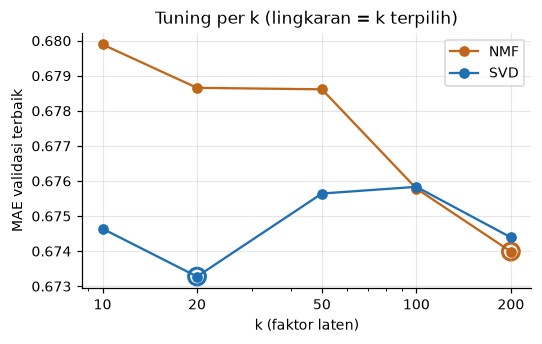

,MAE,gap_gender,dp_g,MAE_baseline,gap_gender_baseline,dp_g_baseline,abs_diff_MAE
SVD,0.686304,0.039051,0.00201,0.686304,0.039051,0.00201,0.000000e+00
NMF,0.781448,0.026853,0.03090,0.781448,0.026853,0.03090,1.110223e-16


Identik dengan baseline: True


In [6]:
if tuning:
    tb = pd.DataFrame(tuning["rows"])
    display(tb.sort_values(["model", "k", "val_MAE"]).groupby(["model", "k"]).head(1))
    print("k terpilih:", tuning["k_selected"])
    print("Parameter terbaik di batas grid / diagnostik k = 300:")
    for kk, vv in tuning.get("grid_edges", {}).items():
        print("  ", kk, ":", vv)
    display(Image(PL.fig_tuning(tuning)))
if control:
    display(pd.DataFrame(control["models"]).T)
    print("Identik dengan baseline:", control.get("identical"))

## 5. Analisis seluruh sel di cache

Analisis menerapkan seluruh aturan keputusan protokol. Bila sebagian tahap belum dijalankan, analisis tetap berjalan pada sel yang ada, tetapi putusan akhir hanya sah setelah semua tahap selesai.

In [7]:
assert tuning is not None, "Jalankan STAGE='tuning' terlebih dahulu."
with rec.stage("analysis"):
    recs = X.load_cells(tuning)          # hanya sel dengan hyperparameter hasil tuning aktif
    BL = X.load_baselines()
    RES = A.run_all(recs, tuning, movies.set_index("movieId")[["title", "genres"]],
                    baselines=BL, users=users)
    RES["failed_cells"] = X.load_failures()
    del recs
if RES["failed_cells"]:
    print("Sel GAGAL (dicatat, tidak dipakai analisis):")
    display(pd.DataFrame([{"berkas": f["file"], "error": f["error"]} for f in RES["failed_cells"]]))
if RES["completeness"]["diverged_cells"]:
    print("Sel DIVERGEN (replikat tidak dipakai uji):", RES["completeness"]["diverged_cells"])
FIGS = PL.all_figures(RES, tuning)
print("Sel:", RES["n_cells"], "| baris:", RES["n_rows"], "| fold:", RES["seeds_available"])
comp = RES["completeness"]
print("Kelengkapan:", "LENGKAP" if comp["complete"] else
      f"BELUM LENGKAP: {comp['missing']} dari {comp['expected_cell_rows']} sel hilang, "
      f"baseline hilang {comp['missing_baseline_folds']}, divergen {len(comp['diverged_cells'])}")
if not comp["complete"]:
    print("Contoh sel hilang:", comp["missing_examples"][:8])
    print("Putusan yang memakai sel tersebut berstatus 'data belum tersedia/lengkap'.")
print("k terpilih:", RES["k_selected"])

Sel: 700 | baris: 2660 | fold: [0, 1, 2, 3, 4]
Kelengkapan: LENGKAP
k terpilih: {'SVD': 20, 'NMF': 200}


### 5.1 Akurasi terhadap alpha untuk setiap k

Rata-rata 5 fold dengan simpangan baku. Membaca grafik: bila kurva NMF turun saat alpha naik tetapi kurva SVD datar, demografi membantu NMF dan tidak membantu SVD. Bandingkan juga antar k: bila keuntungan NMF hilang pada k terbaiknya, keuntungan itu sebagian besar efek regularisasi.

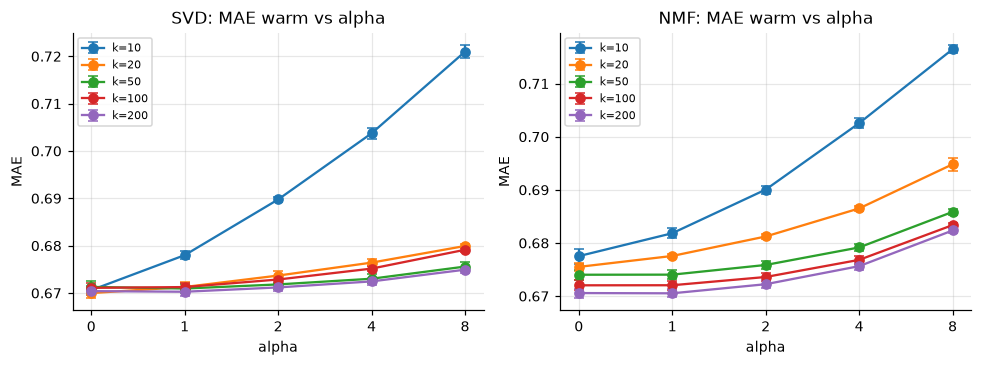

alpha           0       1       2       4       8
model k                                          
NMF   10   0.6775  0.6818  0.6901  0.7026  0.7165
      20   0.6755  0.6776  0.6812  0.6865  0.6948
      50   0.6740  0.6741  0.6759  0.6792  0.6859
      100  0.6720  0.6721  0.6736  0.6768  0.6834
      200  0.6706  0.6705  0.6723  0.6757  0.6824
SVD   10   0.6706  0.6780  0.6898  0.7037  0.7210
      20   0.6700  0.6713  0.6737  0.6764  0.6799
      50   0.6713  0.6710  0.6718  0.6730  0.6756
      100  0.6711  0.6713  0.6729  0.6752  0.6791
      200  0.6704  0.6703  0.6712  0.6725  0.6749

In [8]:
display(Image(str(C.FIG_DIR / "02_akurasi_alpha.png")))
agg = pd.DataFrame(RES["aggregate"])
w = agg[(agg.path == "warm") & (agg.encoding == "full") & (agg.variant == "-")]
display(w.pivot_table(index=["model", "k"], columns="alpha", values="mae").round(4))

### 5.2 Disparitas terhadap alpha (k terpilih)

Gap gender = |MAE F - MAE M|; gap usia = maks(MAE kelompok usia - MAE 25-34). Jalur cold-start memakai kategori input Gender + usia + pekerjaan untuk alpha > 0 dan Default untuk alpha = 0.

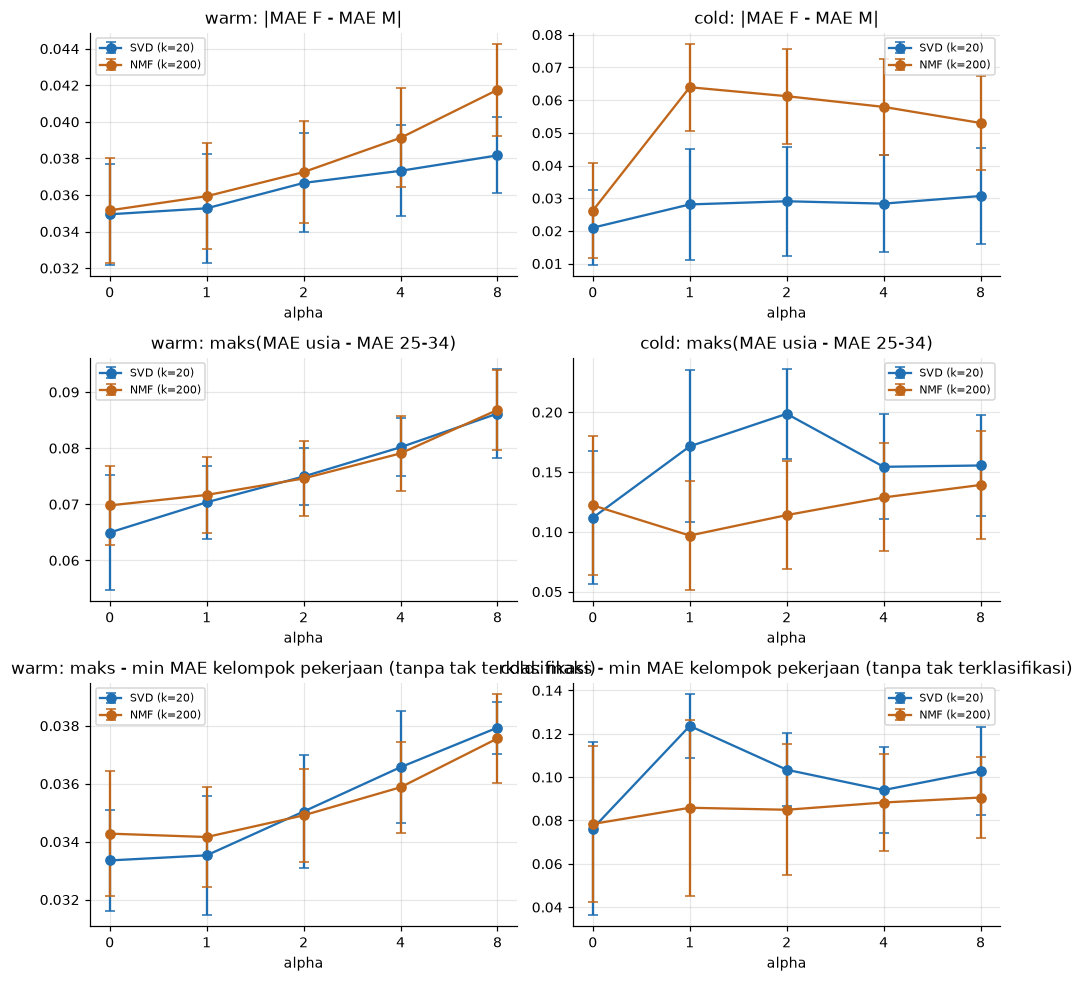

In [9]:
display(Image(str(C.FIG_DIR / "03_disparitas_alpha.png")))

### 5.3 Hipotesis Pertama (F1)

Uji utama: alpha = 0, masing-masing model pada k terpilih, tiga metrik gap berbasis MAE (jalur warm menentukan putusan, jalur cold pendukung). Setiap baris menunjukkan berapa fold yang signifikan (setelah Holm) dengan arah SVD lebih bias atau NMF lebih bias. Selisih indeks ekor (Delta-xi) diuji di keluarga terpisah F1-EVT dan tidak ikut menentukan putusan.

In [10]:
h1 = RES["h1"]
print("PUTUSAN H1:", h1["verdict"])
print("Aturan:", h1["rule"])
display(pd.DataFrame({k: {"putusan": v["label"], "fold SVD>NMF": v["n_sig_positive"],
                          "fold NMF>SVD": v["n_sig_negative"], "fold terestimasi": v["n_seeds_estimable"],
                          "rata selisih SVD-NMF": v["mean_diff_SVD_minus_NMF"]["mean"]}
                      for k, v in h1["decisions"].items()}).T)
print("F1-EVT:")
display(pd.DataFrame({k: {"putusan": v["label"], "fold SVD>NMF": v["n_sig_positive"],
                          "fold NMF>SVD": v["n_sig_negative"],
                          "rata selisih SVD-NMF": v["mean_diff_SVD_minus_NMF"]["mean"]}
                      for k, v in h1["evt"]["decisions"].items()}).T)

PUTUSAN H1: tidak didukung (tidak ada perbedaan signifikan)
Aturan: didukung bila SVD lebih bias pada >= 2 dari 3 metrik gap jalur warm dan tidak ada metrik di mana NMF lebih bias; ditolak bila NMF lebih bias pada >= 2 metrik; tidak didukung bila tidak ada yang berbeda. Delta-xi dilaporkan di keluarga F1-EVT dan tidak ikut menentukan putusan (v3.3).


,putusan,fold SVD>NMF,fold NMF>SVD,fold terestimasi,rata selisih SVD-NMF
warm|gap_gender,tidak berbeda,0,0,5,-0.000219
warm|gap_age_ref,tidak berbeda,0,0,5,-0.004785
warm|gap_occ,tidak berbeda,0,0,5,-0.00087
cold|gap_gender,tidak berbeda,0,0,5,-0.004438
cold|gap_age_ref,tidak berbeda,0,0,5,-0.010076
cold|gap_occ,tidak berbeda,0,0,5,-0.000286


F1-EVT:


,putusan,fold SVD>NMF,fold NMF>SVD,rata selisih SVD-NMF
warm|dxi_gender,tidak berbeda,1,0,0.044855


### 5.4 Pareto akurasi vs fairness

Titik = konfigurasi (model, k, alpha), rata-rata 5 fold dengan error bar. Titik tebal berada di front: tidak ada konfigurasi lain yang lebih baik di kedua sumbu secara konsisten (minimal 4 dari 5 fold). Jawaban "algoritma mana yang lebih seimbang" dibaca dari komposisi front, per atribut dan per jalur.

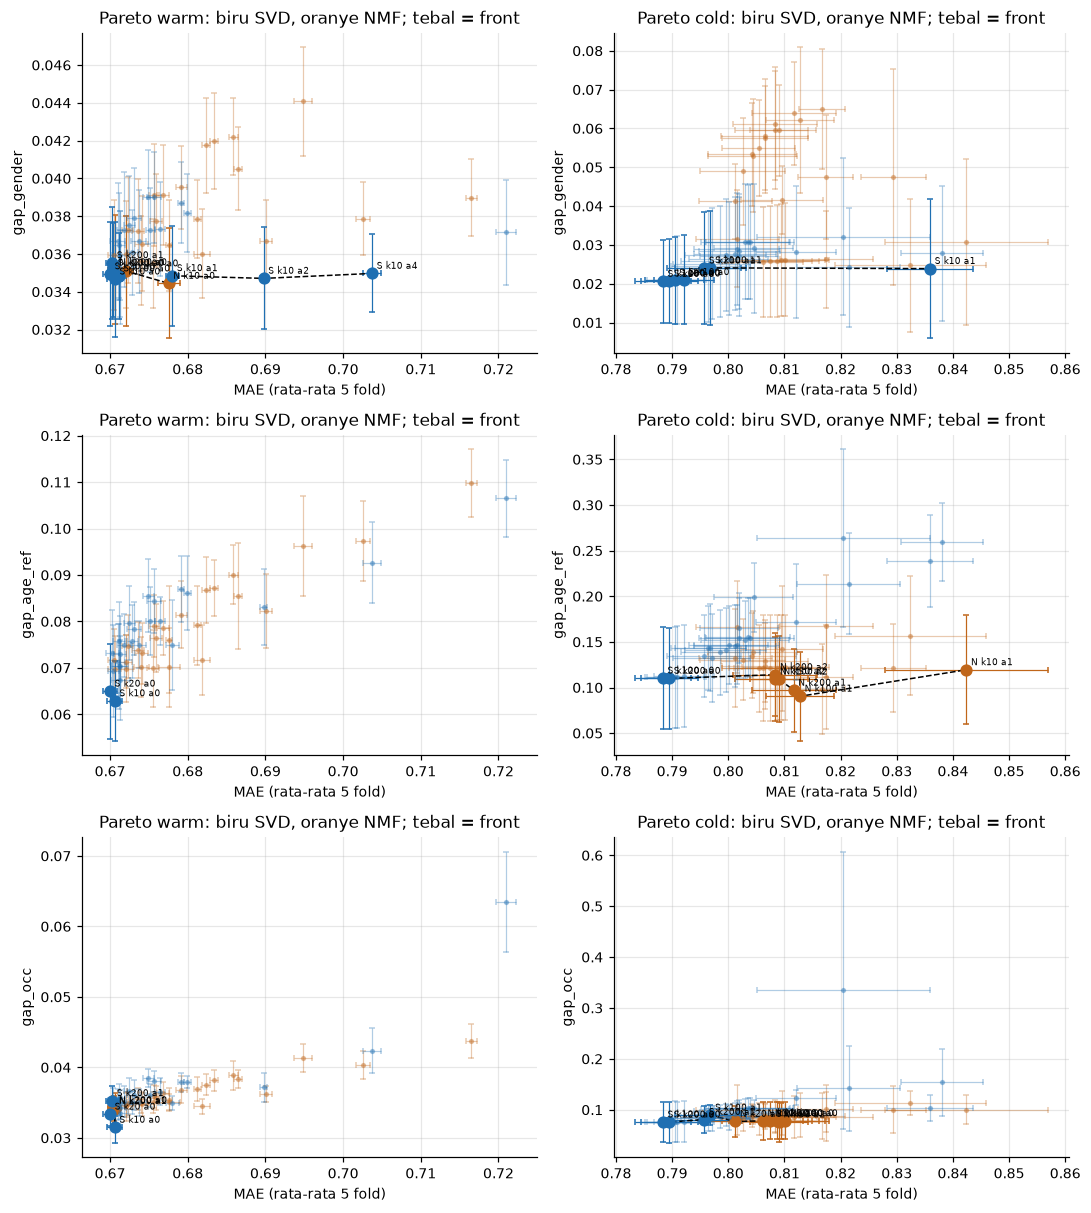

warm  MAE_vs_gap_gender      front SVD=8 NMF=3 | NMF didominasi SVD: 22/25 | SVD didominasi NMF: 13/25
warm  MAE_vs_gap_age_ref     front SVD=2 NMF=0 | NMF didominasi SVD: 25/25 | SVD didominasi NMF: 17/25
warm  MAE_vs_gap_occ         front SVD=3 NMF=2 | NMF didominasi SVD: 23/25 | SVD didominasi NMF: 15/25
warm  MAE_vs_dxi_gender      front SVD=5 NMF=4 | NMF didominasi SVD: 19/25 | SVD didominasi NMF: 18/25
cold  MAE_vs_gap_gender      front SVD=7 NMF=0 | NMF didominasi SVD: 25/25 | SVD didominasi NMF: 2/25
cold  MAE_vs_gap_age_ref     front SVD=2 NMF=6 | NMF didominasi SVD: 16/25 | SVD didominasi NMF: 10/25
cold  MAE_vs_gap_occ         front SVD=4 NMF=7 | NMF didominasi SVD: 16/25 | SVD didominasi NMF: 12/25
cold  MAE_vs_dxi_gender      front SVD=10 NMF=4 | NMF didominasi SVD: 15/20 | SVD didominasi NMF: 3/20


In [11]:
display(Image(str(C.FIG_DIR / "04_pareto.png")))
for path, axes in RES["pareto"].items():
    for ax, v in axes.items():
        print(f"{path:5s} {ax:22s} front SVD={v['n_front_SVD']} NMF={v['n_front_NMF']} | "
              f"NMF didominasi SVD: {v['NMF_points_dominated_by_SVD']}/{v['n_points'].get('NMF')} | "
              f"SVD didominasi NMF: {v['SVD_points_dominated_by_NMF']}/{v['n_points'].get('SVD')}")

### 5.5 Extreme Value Theory: Pickands plot dan selisih indeks ekor

Pickands plot menampilkan estimasi indeks ekor untuk setiap k. Area abu-abu adalah rentang k yang dipakai untuk nilai stabil (1% sampai 5% dari jumlah film, sehingga Pickands paling jauh memakai 20% data teratas). Jumlah eksposur dibatasi ukuran kelompok, sehingga ekor berujung hingga (xi <= 0) mungkin terjadi; Pickands dan Moment konsisten untuk semua tanda xi, sedangkan Hill hanya untuk xi > 0 sehingga tidak dipakai sebagai pembanding. Tabel presisi membandingkan Delta-xi teramati dengan selisih terkecil yang dapat dideteksi (MDE, daya 80%): bila Delta-xi < MDE, hasil "tidak berbeda" tidak boleh dibaca sebagai bukti kesetaraan ekor.

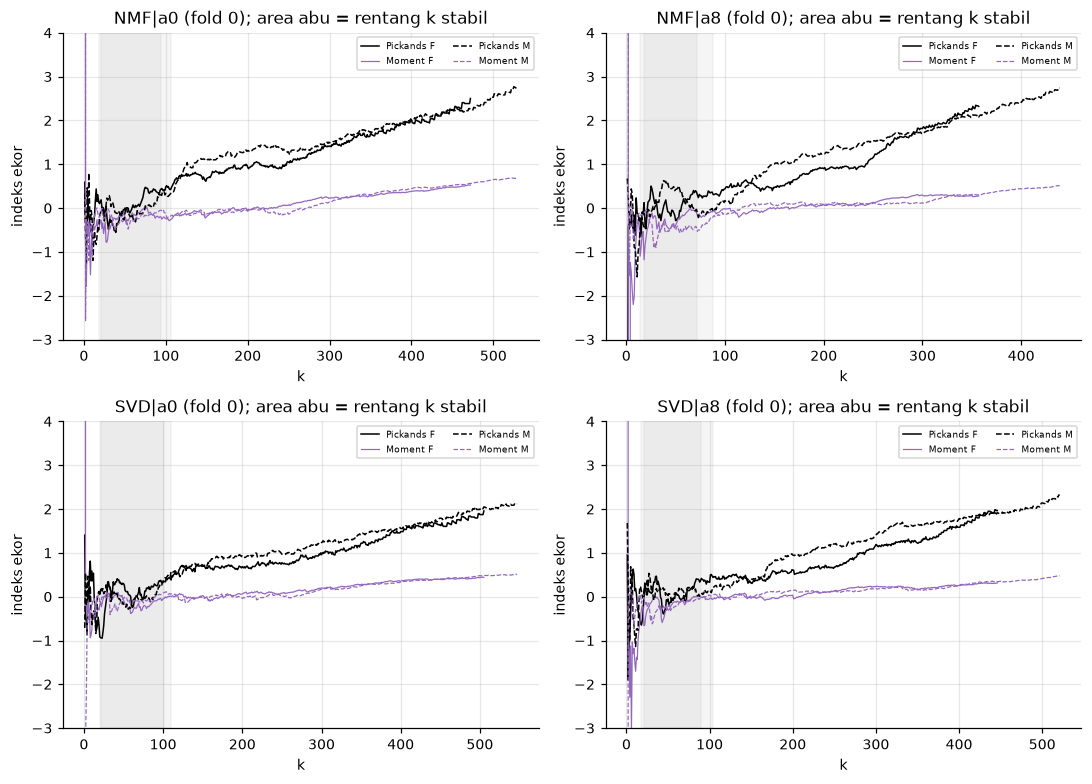

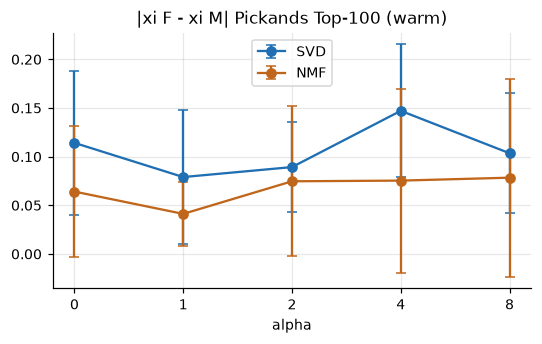

Keterestimasian Pickands (proporsi sel):


,F,M
cold|age|NMF|k10,1.0,1.0
cold|age|NMF|k20,1.0,1.0
cold|age|NMF|k50,1.0,1.0
cold|age|NMF|k100,1.0,1.0
cold|age|NMF|k200,1.0,1.0
...,...,...
warm|-|SVD|k10,1.0,1.0
warm|-|SVD|k20,1.0,1.0
warm|-|SVD|k50,1.0,1.0
warm|-|SVD|k100,1.0,1.0


Kesesuaian estimator: {'spearman_dpickands_vs_dmoment': 0.09354038646318649, 'n_cells': 330, 'share_moment_negative_F': 0.9848484848484849, 'share_pickands_gt_1_F': 0.0, 'share_same_sign_pickands_moment_F': 0.14545454545454545, 'spearman_xi_pickands_vs_moment_F': 0.08117654906106499, 'share_moment_negative_M': 1.0, 'share_pickands_gt_1_M': 0.0, 'share_same_sign_pickands_moment_M': 0.30303030303030304, 'spearman_xi_pickands_vs_moment_M': -0.07262043021021752, 'note': 'Jumlah eksposur dibatasi ukuran kelompok, sehingga ekor berujung hingga (xi <= 0) secara teoretis mungkin. Bila Pickands dan Moment tidak searah, kesimpulan berbasis xi dinyatakan tidak robust.'}
Keandalan EVT: TIDAK ROBUST: Pickands(k) berubah monoton dengan kedalaman k (tanpa wilayah stabil). Delta-xi tidak dipakai untuk klaim keadilan dan dilaporkan sebagai temuan diagnostik


,nilai
n,100
share_same_sign_same_k,0.14
share_same_sign_same_depth,0.84
median_drift_spearman,0.979741
share_cells_drift_gt_0_5,1.0
median_share_saturated_items,0.0
median_share_exposure_top1pct,0.125311
robust,False
verdict,TIDAK ROBUST: Pickands(k) berubah monoton deng...


,model,alpha,gender,pickands,moment_same_k,moment_same_depth,drift_spearman,share_saturated_items,share_exposure_top1pct
0,NMF,0,F,0.045,-0.261,0.044,0.986,0.000,0.126
1,NMF,0,M,0.009,-0.220,-0.006,0.987,0.000,0.146
2,NMF,1,F,0.086,-0.180,0.073,0.977,0.000,0.118
3,NMF,1,M,0.045,-0.292,0.051,0.984,0.001,0.137
4,NMF,2,F,0.137,-0.193,0.082,0.966,0.000,0.117
5,NMF,2,M,0.075,-0.297,0.066,0.983,0.001,0.138
6,NMF,4,F,0.127,-0.233,0.075,0.949,0.000,0.114
7,NMF,4,M,0.085,-0.337,0.081,0.983,0.001,0.135
8,NMF,8,F,0.094,-0.320,0.042,0.949,0.000,0.112
9,NMF,8,M,0.116,-0.395,0.086,0.979,0.001,0.133


Presisi EVT (rata-rata fold):


,xi_F,xi_M,boot_sd_F,boot_sd_M,asym_sd_F,asym_sd_M,mde_boot,mde_asym,observed_dxi
SVD|a0,0.126,0.011,0.030,0.027,0.234,0.223,0.114,0.906,0.114
SVD|a1,0.091,0.012,0.037,0.021,0.237,0.223,0.120,0.911,0.079
SVD|a2,0.132,0.074,0.041,0.020,0.238,0.223,0.127,0.915,0.089
SVD|a4,0.150,0.105,0.036,0.021,0.242,0.226,0.118,0.929,0.147
SVD|a8,0.108,0.105,0.041,0.022,0.249,0.231,0.132,0.952,0.104
NMF|a0,0.045,0.009,0.035,0.021,0.241,0.226,0.116,0.926,0.064
NMF|a1,0.086,0.045,0.039,0.024,0.251,0.235,0.130,0.962,0.041
NMF|a2,0.137,0.075,0.035,0.022,0.257,0.238,0.117,0.981,0.075
NMF|a4,0.127,0.085,0.030,0.022,0.265,0.244,0.105,1.009,0.075
NMF|a8,0.094,0.116,0.036,0.025,0.279,0.253,0.124,1.056,0.078


,F|0.005-0.025|pickands,F|0.005-0.025|moment,F|0.01-0.05|pickands,F|0.01-0.05|moment,F|0.025-0.1|pickands,F|0.025-0.1|moment,F|0.05-0.2|pickands,F|0.05-0.2|moment,M|0.005-0.025|pickands,M|0.005-0.025|moment,M|0.01-0.05|pickands,M|0.01-0.05|moment,M|0.025-0.1|pickands,M|0.025-0.1|moment,M|0.05-0.2|pickands,M|0.05-0.2|moment
SVD|a0,0.040,-0.148,0.126,-0.148,0.472,-0.061,0.976,0.112,-0.069,-0.065,0.011,-0.084,0.745,-0.069,1.170,0.029
SVD|a1,0.239,-0.322,0.091,-0.106,0.323,0.083,0.722,0.146,0.003,-0.082,0.012,-0.085,0.512,-0.011,1.059,0.059
SVD|a2,0.252,-0.287,0.132,-0.127,0.265,0.087,0.725,0.156,0.032,-0.088,0.074,-0.087,0.403,-0.007,1.107,0.092
SVD|a4,0.230,-0.257,0.150,-0.156,0.247,0.042,0.705,0.154,0.027,-0.082,0.105,-0.095,0.407,-0.005,1.148,0.120
SVD|a8,0.157,-0.294,0.108,-0.182,0.280,0.011,0.716,0.126,0.016,-0.126,0.105,-0.122,0.431,-0.026,1.175,0.123
NMF|a0,-0.098,-0.390,0.045,-0.261,0.630,-0.139,1.064,0.073,-0.087,-0.283,0.009,-0.220,0.919,-0.136,1.486,0.015
NMF|a1,-0.081,-0.389,0.086,-0.180,0.311,-0.065,1.091,0.085,0.051,-0.352,0.045,-0.292,0.691,-0.053,1.386,0.065
NMF|a2,-0.021,-0.393,0.137,-0.193,0.305,-0.057,0.908,0.092,0.112,-0.394,0.075,-0.297,0.608,-0.036,1.323,0.079
NMF|a4,-0.059,-0.410,0.127,-0.233,0.314,-0.063,0.768,0.084,0.114,-0.415,0.085,-0.337,0.545,-0.030,1.283,0.091
NMF|a8,-0.103,-0.436,0.094,-0.320,0.319,-0.139,0.739,0.051,-0.040,-0.396,0.116,-0.395,0.444,-0.085,1.322,0.100


In [12]:
display(Image(str(C.FIG_DIR / "05_pickands_plot.png")))
display(Image(str(C.FIG_DIR / "06_delta_xi.png")))
print("Keterestimasian Pickands (proporsi sel):")
display(pd.DataFrame(RES["evt"]["estimability"]).T)
print("Kesesuaian estimator:", RES["evt_agreement"])
er = RES.get("evt_robustness", {})
if er.get("available"):
    print("Keandalan EVT:", er["summary"]["verdict"])
    display(pd.Series(er["summary"]).to_frame("nilai"))
    display(pd.DataFrame(er["per_config"]).round(3))
print("Presisi EVT (rata-rata fold):")
display(pd.DataFrame(RES["evt_precision"]["results"]).T.round(3))
sens = RES["evt_sensitivity"]["results"]
if sens:
    display(pd.DataFrame(sens).T.round(3))

### 5.6 Efek alpha (F2) dan bobot demografi aman

Bobot aman = alpha yang batas atas CI 95% kenaikan setiap metrik gap (gender, usia, pekerjaan) tidak melebihi 10% dari nilainya pada alpha = 0, dan MAE tidak memburuk lebih dari 0,005, pada minimal 4 dari 5 fold; dihitung per encoding dan per jalur. Aman berarti tidak merugikan, bukan bermanfaat. Delta-xi dilaporkan deskriptif. Bobot relatif terhadap profil pengguna ikut ditampilkan.

In [13]:
for k, v in RES["safe_alpha"]["results"].items():
    print(f"{k:22s}: {v['statement']}")
    display(pd.DataFrame([{kk: r[kk] for kk in ["alpha", "n_seeds_pass", "safe", "median_relative_weight"]}
                          for r in v["table"]]))
ae = RES["alpha_effect"]["decisions"]
display(pd.DataFrame({k: {"putusan": v["label"], "fold naik": v["n_sig_positive"], "fold turun": v["n_sig_negative"],
                          "rata selisih": v["mean_diff"]["mean"]} for k, v in ae.items()}).T)
print("F2-EVT:")
display(pd.DataFrame({k: {"putusan": v["label"], "fold naik": v["n_sig_positive"], "fold turun": v["n_sig_negative"],
                          "rata selisih": v["mean_diff"]["mean"]}
                      for k, v in RES["alpha_effect"]["evt"]["decisions"].items()}).T)

SVD|warm|full         : tidak ada bobot demografi yang aman pada konfigurasi ini


,alpha,n_seeds_pass,safe,median_relative_weight
0,1,1,False,0.154188
1,2,0,False,0.267179
2,4,0,False,0.421691
3,8,0,False,0.593223


SVD|warm|member5      : alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)


,alpha,n_seeds_pass,safe,median_relative_weight
0,1,5,True,0.037595
1,2,5,True,0.072465
2,4,5,True,0.135138
3,8,5,True,0.238099


SVD|warm|membermean   : alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)


,alpha,n_seeds_pass,safe,median_relative_weight
0,1,5,True,0.037595
1,2,5,True,0.072465
2,4,5,True,0.135138
3,8,5,True,0.238099


... (17 outputs left out)

,alpha,n_seeds_pass,safe,median_relative_weight
0,1,0,False,None
1,2,0,False,None
2,4,0,False,None
3,8,0,False,None


,putusan,fold naik,fold turun,rata selisih
SVD|warm|a1|gap_gender,tidak berubah signifikan,0,0,0.000329
SVD|warm|a1|gap_age_ref,tidak berubah signifikan,0,0,0.005349
SVD|warm|a1|gap_occ,tidak berubah signifikan,0,0,-0.00042
SVD|warm|a2|gap_gender,tidak berubah signifikan,0,0,0.001718
SVD|warm|a2|gap_age_ref,tidak berubah signifikan,1,0,0.00994
SVD|warm|a2|gap_occ,tidak berubah signifikan,0,0,0.001613
SVD|warm|a4|gap_gender,tidak berubah signifikan,0,0,0.002384
SVD|warm|a4|gap_age_ref,tidak berubah signifikan,2,0,0.015137
SVD|warm|a4|gap_occ,tidak berubah signifikan,0,0,0.003477
SVD|warm|a8|gap_gender,tidak berubah signifikan,0,0,0.003227


F2-EVT:


,putusan,fold naik,fold turun,rata selisih
SVD|warm|a1|dxi_gender,tidak berubah signifikan,0,0,-0.044184
SVD|warm|a2|dxi_gender,tidak berubah signifikan,0,0,-0.05282
SVD|warm|a4|dxi_gender,tidak berubah signifikan,0,0,0.007771
SVD|warm|a8|dxi_gender,tidak berubah signifikan,0,0,-0.009458
NMF|warm|a1|dxi_gender,tidak berubah signifikan,0,0,-0.01197
NMF|warm|a2|dxi_gender,tidak berubah signifikan,0,0,-0.017638
NMF|warm|a4|dxi_gender,tidak berubah signifikan,0,0,-0.005451
NMF|warm|a8|dxi_gender,tidak berubah signifikan,0,0,0.014148


### 5.7 Klaim pengguna baru (F3)

Excess gap relatif = (gap teramati - rata-rata gap bila label kelompok diacak) / MAE. F3 membandingkan pengguna fold cold-start saat menjadi pengguna baru dengan PENGGUNA YANG SAMA saat menjadi pengguna lama (bootstrap berpasangan). F3b menjawab pertanyaan yang lebih praktis: apakah profil demografi (gender + usia + pekerjaan) lebih baik daripada rekomendasi Default pada pengguna baru? Nilai negatif berarti profil lebih baik.

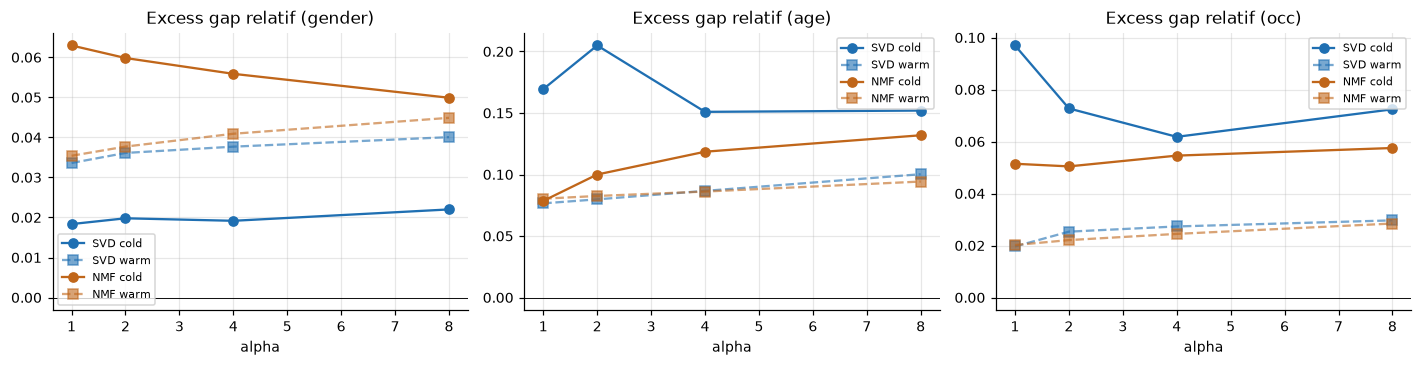

,klaim sah,fold signifikan,relx cold,relx warm (pengguna sama)
SVD|a1|gender,False,0,0.01835,0.033606
SVD|a1|age,False,1,0.169411,0.076555
SVD|a1|occ,False,0,0.096975,0.019647
SVD|a2|gender,False,0,0.019795,0.036117
SVD|a2|age,False,2,0.204886,0.079819
SVD|a2|occ,False,0,0.072745,0.025348
SVD|a4|gender,False,0,0.019168,0.037687
SVD|a4|age,False,0,0.150933,0.086692
SVD|a4|occ,False,0,0.061827,0.027347
SVD|a8|gender,False,0,0.02201,0.040063


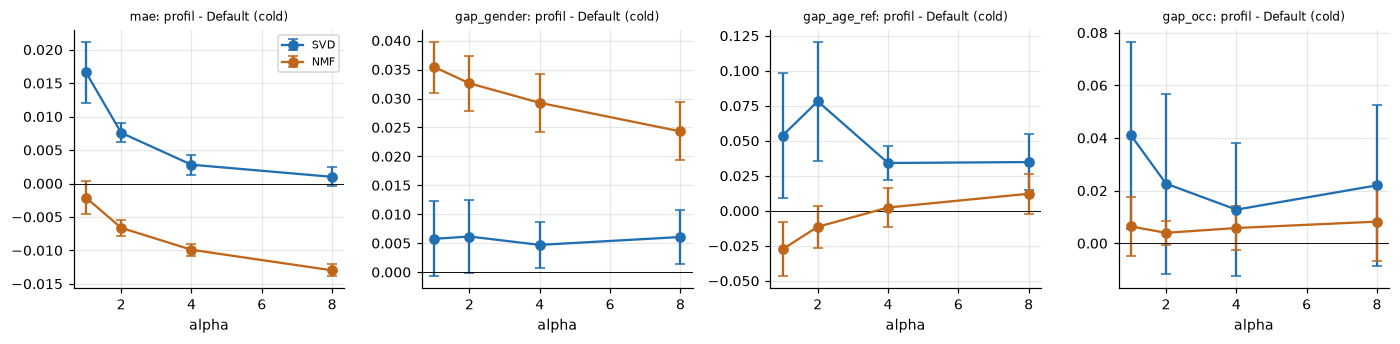

,putusan,fold naik,fold turun,rata (profil - Default)
SVD|a1|mae,profil demografi memperburuk,5,0,0.016609
SVD|a1|gap_gender,tidak berbeda,0,0,0.00576
SVD|a1|gap_age_ref,tidak berbeda,0,0,0.053776
SVD|a1|gap_occ,tidak berbeda,0,0,0.04111
SVD|a2|mae,profil demografi memperburuk,5,0,0.007581
SVD|a2|gap_gender,tidak berbeda,0,0,0.006159
SVD|a2|gap_age_ref,tidak berbeda,1,0,0.07822
SVD|a2|gap_occ,tidak berbeda,0,0,0.022673
SVD|a4|mae,tidak berbeda,1,0,0.002812
SVD|a4|gap_gender,tidak berbeda,0,0,0.00471


F3b pada encoding hanya-anggota:


,putusan,rata (profil - Default)
member5|SVD|a1|mae,profil demografi memperbaiki,-0.006451
member5|SVD|a1|gap_gender,tidak berbeda,-0.001411
member5|SVD|a1|gap_age_ref,tidak berbeda,-0.004123
member5|SVD|a1|gap_occ,tidak berbeda,0.000192
member5|SVD|a2|mae,profil demografi memperbaiki,-0.005844
...,...,...
membermean|NMF|a4|gap_occ,tidak berbeda,-0.003619
membermean|NMF|a8|mae,profil demografi memperbaiki,-0.012187
membermean|NMF|a8|gap_gender,tidak berbeda,-0.001169
membermean|NMF|a8|gap_age_ref,tidak berbeda,-0.007291


In [14]:
display(Image(str(C.FIG_DIR / "08_pengguna_baru.png")))
nu = RES["new_users"]["decisions"]
display(pd.DataFrame({k: {"klaim sah": v["claim_valid"], "fold signifikan": v["n_sig_positive"],
                          "relx cold": v["mean_relx_cold"]["mean"],
                          "relx warm (pengguna sama)": v["mean_relx_warm_same_users"]["mean"]}
                      for k, v in nu.items()}).T)
display(Image(str(C.FIG_DIR / "13_profil_vs_default_cold.png")))
npf = RES["new_user_profile"]
display(pd.DataFrame({k: {"putusan": v["label"], "fold naik": v["n_sig_positive"], "fold turun": v["n_sig_negative"],
                          "rata (profil - Default)": v["mean_diff"]["mean"]} for k, v in npf["decisions"].items()}).T)
if "ablation" in npf:
    print("F3b pada encoding hanya-anggota:")
    display(pd.DataFrame({k: {"putusan": v["label"], "rata (profil - Default)": v["mean_diff"]["mean"]}
                          for k, v in npf["ablation"]["decisions"].items()}).T)

### 5.8 Amplifikasi perbedaan genre (F4, jalur warm)

A(alpha) = JS(rekomendasi F, rekomendasi M) - JS(historis F, historis M). Yang diuji adalah efek demografi A(alpha) - A(0). Jalur cold-start tidak dipakai sebagai bukti amplifikasi karena satu daftar bersama per profil membuat perbandingan dengan selera historis tidak setara; untuk cold-start dipakai miscalibration per pengguna.

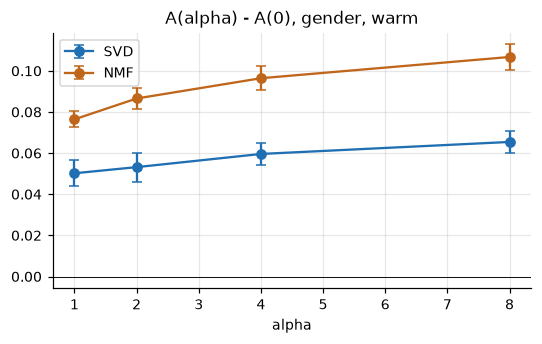

,klaim sah,fold signifikan,rata A(a)-A(0)
SVD|a1,True,5,0.050217
SVD|a2,True,5,0.053199
SVD|a4,True,5,0.059605
SVD|a8,True,5,0.065446
NMF|a1,True,5,0.076437
NMF|a2,True,5,0.086575
NMF|a4,True,5,0.096433
NMF|a8,True,5,0.106757


In [15]:
display(Image(str(C.FIG_DIR / "09_amplifikasi.png")))
am = RES["amplification"]["decisions"]
display(pd.DataFrame({k: {"klaim sah": v["claim_valid"], "fold signifikan": v["n_sig_positive"],
                          "rata A(a)-A(0)": v["mean_A_alpha_minus_A0"]["mean"]} for k, v in am.items()}).T)

### 5.9 Mekanisme nilai negatif (F5) dan efek encoding (F5b)

Bila cos(F, M) SVD tetap jauh negatif pada encoding hanya-anggota (yang tidak memaksa F dan M berlawanan), pola berlawanan berasal dari sifat SVD itu sendiri. Bila mendekati nol atau positif, pola itu artefak encoding. Cosinus NMF selalu >= 0 secara matematis. F5b menguji langsung apakah encoding hanya-anggota menghasilkan MAE, gap, dan amplifikasi yang berbeda dari encoding full pada alpha yang sama (nilai negatif = hanya-anggota lebih baik), pada pengguna lama dan pengguna baru.

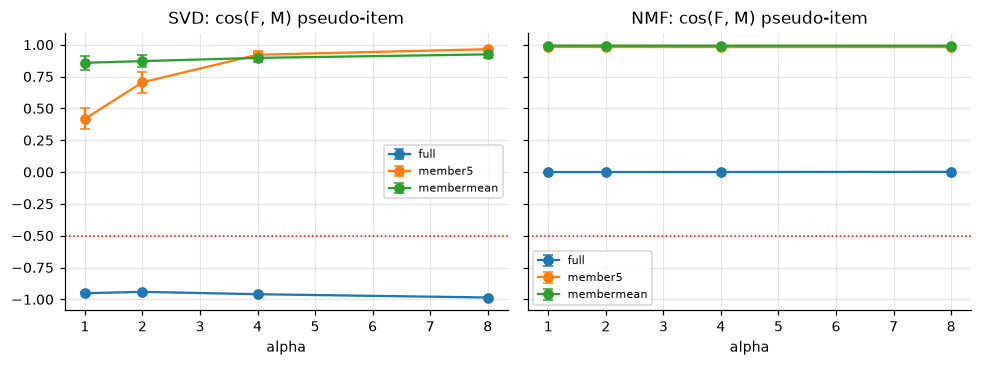

Mekanisme didukung: False | {'member5': {'n_alpha_hold': 0, 'n_alpha': 4, 'holds': False}, 'membermean': {'n_alpha_hold': 0, 'n_alpha': 4, 'holds': False}, 'full': {'n_alpha_hold': 4, 'n_alpha': 4, 'holds': True}}


,cos mean,CI bawah,CI atas
SVD|full|a1,-0.951719,-0.960150,-0.943289
SVD|full|a2,-0.940823,-0.942861,-0.938784
SVD|full|a4,-0.959385,-0.960557,-0.958212
SVD|full|a8,-0.985344,-0.985534,-0.985155
SVD|member5|a1,0.417699,0.334614,0.500784
SVD|member5|a2,0.705415,0.622367,0.788463
SVD|member5|a4,0.921634,0.894515,0.948753
SVD|member5|a8,0.965297,0.958191,0.972403
SVD|membermean|a1,0.858163,0.804574,0.911752
SVD|membermean|a2,0.871871,0.826364,0.917378


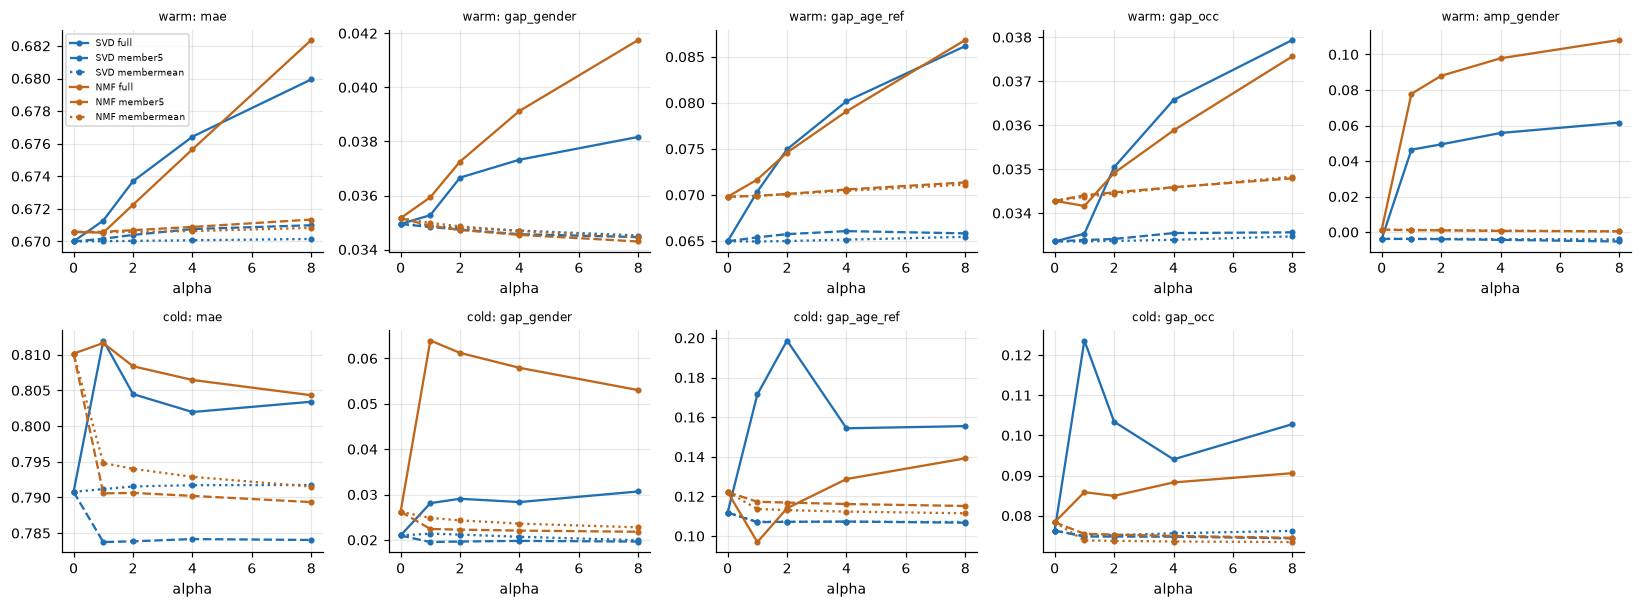

F5b warm|member5


,putusan,fold naik,fold turun,rata (hanya-anggota - full)
SVD|a1|mae,tidak berbeda,0,2,-0.001118
SVD|a1|gap_gender,tidak berbeda,0,0,-0.00044
SVD|a1|gap_age_ref,tidak berbeda,0,0,-0.004932
SVD|a1|gap_occ,tidak berbeda,0,0,0.00045
SVD|a1|amp_gender,hanya-anggota lebih baik,0,5,-0.050219
SVD|a2|mae,hanya-anggota lebih baik,0,5,-0.003295
SVD|a2|gap_gender,tidak berbeda,0,0,-0.001924
SVD|a2|gap_age_ref,tidak berbeda,0,1,-0.009169
SVD|a2|gap_occ,tidak berbeda,0,0,-0.001564
SVD|a2|amp_gender,hanya-anggota lebih baik,0,5,-0.053334


F5b warm|membermean


,putusan,fold naik,fold turun,rata (hanya-anggota - full)
SVD|a1|mae,tidak berbeda,0,2,-0.001266
SVD|a1|gap_gender,tidak berbeda,0,0,-0.000402
SVD|a1|gap_age_ref,tidak berbeda,0,0,-0.005378
SVD|a1|gap_occ,tidak berbeda,0,0,0.000415
SVD|a1|amp_gender,hanya-anggota lebih baik,0,5,-0.050194
SVD|a2|mae,hanya-anggota lebih baik,0,5,-0.003661
SVD|a2|gap_gender,tidak berbeda,0,0,-0.001857
SVD|a2|gap_age_ref,tidak berbeda,0,1,-0.009923
SVD|a2|gap_occ,tidak berbeda,0,0,-0.001619
SVD|a2|amp_gender,hanya-anggota lebih baik,0,5,-0.053184


F5b cold|member5


,putusan,fold naik,fold turun,rata (hanya-anggota - full)
SVD|a1|mae,hanya-anggota lebih baik,0,5,-0.028246
SVD|a1|gap_gender,tidak berbeda,0,0,-0.008043
SVD|a1|gap_age_ref,tidak berbeda,0,2,-0.0597
SVD|a1|gap_occ,tidak berbeda,0,0,-0.041028
SVD|a2|mae,hanya-anggota lebih baik,0,5,-0.020637
SVD|a2|gap_gender,tidak berbeda,0,0,-0.008634
SVD|a2|gap_age_ref,tidak berbeda,0,2,-0.084951
SVD|a2|gap_occ,tidak berbeda,0,0,-0.022536
SVD|a4|mae,hanya-anggota lebih baik,0,5,-0.01781
SVD|a4|gap_gender,tidak berbeda,0,0,-0.007393


F5b cold|membermean


,putusan,fold naik,fold turun,rata (hanya-anggota - full)
SVD|a1|mae,hanya-anggota lebih baik,0,5,-0.020812
SVD|a1|gap_gender,tidak berbeda,0,0,-0.006159
SVD|a1|gap_age_ref,tidak berbeda,0,2,-0.059541
SVD|a1|gap_occ,tidak berbeda,0,0,-0.042487
SVD|a2|mae,hanya-anggota lebih baik,0,5,-0.012945
SVD|a2|gap_gender,tidak berbeda,0,0,-0.007104
SVD|a2|gap_age_ref,tidak berbeda,0,3,-0.084966
SVD|a2|gap_occ,tidak berbeda,0,0,-0.023642
SVD|a4|mae,hanya-anggota lebih baik,0,5,-0.010253
SVD|a4|gap_gender,tidak berbeda,0,0,-0.006502


In [16]:
display(Image(str(C.FIG_DIR / "07_mekanisme_cos.png")))
me = RES["mechanism"]
print("Mekanisme didukung:", me["mechanism_supported"], "|", me["verdict_per_encoding"])
display(pd.DataFrame({k: {"cos mean": v["mean"], "CI bawah": v["ci95_t"][0], "CI atas": v["ci95_t"][1]}
                      for k, v in me["cos_F_M"].items()}).T)
display(Image(str(C.FIG_DIR / "12_encoding.png")))
for fam_name, fam in RES["encoding_effect"].items():
    print("F5b", fam_name)
    display(pd.DataFrame({k: {"putusan": v["label"], "fold naik": v["n_sig_positive"], "fold turun": v["n_sig_negative"],
                              "rata (hanya-anggota - full)": v["mean_diff"]["mean"]}
                          for k, v in fam["decisions"].items()}).T)

### 5.10 Hipotesis Kedua (F6), efek pekerjaan sebagai input (F7), dan kebocoran

H2 dilaporkan deskriptif: korelasi Spearman parsial antara akurasi (-MAE) dan disparitas lintas 25 konfigurasi k x alpha di dalam setiap algoritma, dengan alpha dikontrol. Titik konfigurasi memakai data dan pengguna yang sama sehingga tidak saling bebas; nilai p terlalu optimistis dan arah dibaca bersama front Pareto. F7 membandingkan konfigurasi utama (gender + usia + pekerjaan) dengan ablation tanpa pekerjaan (gender + usia) pada k terpilih; karena kelompok pekerjaan berkorelasi dengan usia, hanya perbandingan ini yang mengukur kontribusi marginal pekerjaan. Kebocoran kelompok pekerjaan hanya diuji pada konfigurasi tanpa pekerjaan sebagai input (alpha = 0 dan ablation gender + usia).

H2 (deskriptif), arah: {'SVD': 'arah searah (akurasi dan keadilan sejalan)', 'NMF': 'arah searah (akurasi dan keadilan sejalan)'}


,partial_rho,p,n_points,n_k,p_holm
SVD|gap_gender,0.648276,0.000613,25.0,5.0,0.002451
SVD|gap_age_ref,-0.676061,0.000287,25.0,5.0,0.001437
SVD|gap_occ,-0.228162,0.283578,25.0,5.0,0.567156
SVD|dxi_gender,-0.520791,0.009073,25.0,5.0,0.027220
NMF|gap_gender,0.081056,0.706535,25.0,5.0,0.706535
NMF|gap_age_ref,-0.794299,0.000004,25.0,5.0,0.000029
NMF|gap_occ,-0.724331,0.000063,25.0,5.0,0.000377
NMF|dxi_gender,-0.790272,0.000004,25.0,5.0,0.000030


,rho,n_k
SVD|gap_gender|a0,-0.2,5.0
SVD|gap_gender|a1,0.8,5.0
SVD|gap_gender|a2,0.5,5.0
SVD|gap_gender|a4,0.8,5.0
SVD|gap_gender|a8,1.0,5.0
SVD|gap_age_ref|a0,-0.3,5.0
SVD|gap_age_ref|a1,-0.1,5.0
SVD|gap_age_ref|a2,-0.3,5.0
SVD|gap_age_ref|a4,-0.9,5.0
SVD|gap_age_ref|a8,-0.8,5.0


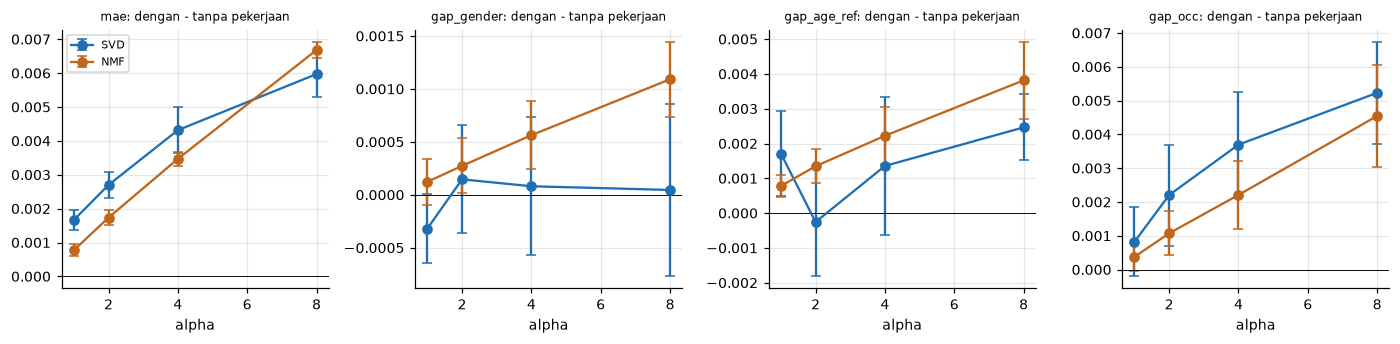

,putusan,fold naik,fold turun,rata (dengan - tanpa)
SVD|a1|mae,menambah pekerjaan menaikkan nilai,5,0,0.001666
SVD|a1|gap_gender,tidak berbeda,0,0,-0.000318
SVD|a1|gap_age_ref,tidak berbeda,0,0,0.001714
SVD|a1|gap_occ,tidak berbeda,0,0,0.000821
SVD|a2|mae,menambah pekerjaan menaikkan nilai,5,0,0.002699
SVD|a2|gap_gender,tidak berbeda,0,0,0.000147
SVD|a2|gap_age_ref,tidak berbeda,0,0,-0.000255
SVD|a2|gap_occ,tidak berbeda,0,0,0.002205
SVD|a4|mae,menambah pekerjaan menaikkan nilai,5,0,0.004317
SVD|a4|gap_gender,tidak berbeda,0,0,0.000081


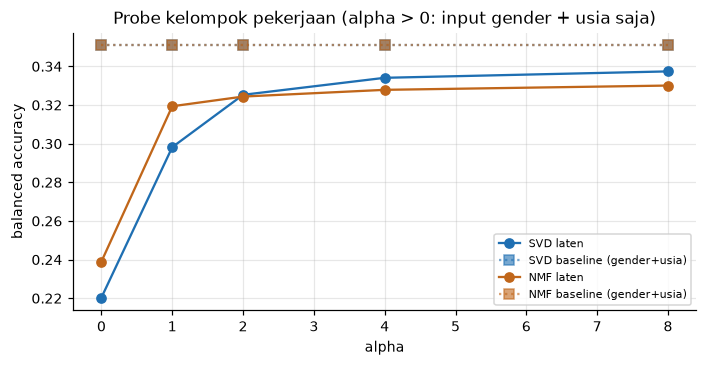

,laten,baseline,selisih,bocor
SVD|utama|a0,0.220391,0.35084,-0.130449,False
SVD|input_gender_usia|a1,0.298207,0.35084,-0.052632,False
SVD|input_gender_usia|a2,0.325299,0.35084,-0.025541,False
SVD|input_gender_usia|a4,0.334105,0.35084,-0.016734,False
SVD|input_gender_usia|a8,0.337421,0.35084,-0.013419,False
NMF|utama|a0,0.239022,0.35084,-0.111817,False
NMF|input_gender_usia|a1,0.319383,0.35084,-0.031457,False
NMF|input_gender_usia|a2,0.324397,0.35084,-0.026443,False
NMF|input_gender_usia|a4,0.327877,0.35084,-0.022963,False
NMF|input_gender_usia|a8,0.330094,0.35084,-0.020746,False


In [17]:
h2 = RES["h2"]
print("H2 (deskriptif), arah:", h2["direction"])
display(pd.DataFrame({k: v for k, v in h2["tests"].items() if v}).T)
display(pd.DataFrame({k: v for k, v in h2["per_alpha_descriptive"].items() if v}).T)
oe = RES["occupation_effect"]["decisions"]
display(Image(str(C.FIG_DIR / "11_efek_pekerjaan.png")))
display(pd.DataFrame({k: {"putusan": v["label"], "fold naik": v["n_sig_positive"], "fold turun": v["n_sig_negative"],
                          "rata (dengan - tanpa)": v["mean_diff_with_minus_without"]["mean"]} for k, v in oe.items()}).T)
display(Image(str(C.FIG_DIR / "10_kebocoran_pekerjaan.png")))
display(pd.DataFrame({k: {"laten": v["latent_bal_acc"]["mean"], "baseline": v["baseline_bal_acc"]["mean"],
                          "selisih": v["diff_latent_minus_baseline"]["mean"], "bocor": v["leak"]}
                      for k, v in RES["leakage"]["results"].items()}).T)

### 5.11 Pembanding BaselineOnly dan perancu aktivitas (F8)

Prediktor bias saja (mu + b_u + b_i) tidak memiliki faktor laten, sehingga gap kelompoknya mencerminkan perbedaan yang sudah ada pada pola rating. F8 menguji apakah gap SVD/NMF melampaui gap baseline itu (nilai positif = faktorisasi menambah disparitas). Tabel strata menampilkan gap per kuartil jumlah rating latih (Q1 paling sedikit) untuk model dan baseline.

In [18]:
cf = RES["confound"]
if cf.get("decisions"):
    display(pd.DataFrame({k: {"putusan": v["label"], "fold naik": v["n_sig_positive"], "fold turun": v["n_sig_negative"],
                              "rata (model - baseline)": v["mean_diff"]["mean"]} for k, v in cf["decisions"].items()}).T)
    display(pd.DataFrame({k: v["mean"] for k, v in cf["baseline_points"].items()}, index=["baseline"]).T)
    display(pd.DataFrame(cf["activity_strata_descriptive"]).round(4))
    print("F8-relatif (gap / MAE):")
    display(pd.DataFrame({k: {"putusan": v["label"], "fold naik": v["n_sig_positive"], "fold turun": v["n_sig_negative"],
                              "rata (model - baseline)": v["mean_diff"]["mean"]}
                          for k, v in cf["relative"]["decisions"].items()}).T)
else:
    print("Baseline belum tersedia: jalankan STAGE = 'baseline'.")

,putusan,fold naik,fold turun,rata (model - baseline)
SVD|warm|gap_gender,tidak berbeda,2,0,0.006615
SVD|warm|gap_age_ref,disparitas model lebih kecil dari baseline,0,4,-0.030447
SVD|warm|gap_occ,tidak berbeda,0,1,-0.014672
SVD|cold|gap_gender,tidak berbeda,0,0,0.001072
SVD|cold|gap_age_ref,tidak berbeda,0,0,0.005476
SVD|cold|gap_occ,tidak berbeda,0,0,0.001678
NMF|warm|gap_gender,tidak berbeda,3,0,0.006834
NMF|warm|gap_age_ref,tidak berbeda,0,3,-0.025661
NMF|warm|gap_occ,tidak berbeda,0,0,-0.013802
NMF|cold|gap_gender,tidak berbeda,0,0,0.00551


,baseline
baseline|warm|gap_gender,0.028333
baseline|warm|gap_age_ref,0.095352
baseline|warm|gap_occ,0.048703
baseline|warm|rgap_gender,0.039387
baseline|warm|rgap_age_ref,0.132555
baseline|warm|rgap_occ,0.067708
baseline|warm|mae,0.719326
baseline|cold|gap_gender,0.019670
baseline|cold|gap_age_ref,0.105665
baseline|cold|gap_occ,0.070855


,SVD,NMF
model|Q1|gap_gender_signed,0.0335,0.0301
model|Q1|gap_age_ref,0.0600,0.0640
model|Q2|gap_gender_signed,0.0176,0.0201
model|Q2|gap_age_ref,0.0910,0.1016
model|Q3|gap_gender_signed,0.0428,0.0441
model|Q3|gap_age_ref,0.0605,0.0667
model|Q4|gap_gender_signed,0.0306,0.0301
model|Q4|gap_age_ref,0.0430,0.0451
baseline|Q1|gap_gender_signed,0.0265,0.0265
baseline|Q1|gap_age_ref,0.0743,0.0743


F8-relatif (gap / MAE):


,putusan,fold naik,fold turun,rata (model - baseline)
SVD|warm|rgap_gender,model menambah disparitas di atas baseline,5,0,0.012773
SVD|warm|rgap_age_ref,tidak berbeda,0,0,-0.035638
SVD|warm|rgap_occ,tidak berbeda,0,0,-0.016589
SVD|cold|rgap_gender,tidak berbeda,0,0,0.000978
SVD|cold|rgap_age_ref,tidak berbeda,0,0,0.005116
SVD|cold|rgap_occ,tidak berbeda,0,0,0.000748
NMF|warm|rgap_gender,model menambah disparitas di atas baseline,5,0,0.013055
NMF|warm|rgap_age_ref,tidak berbeda,0,0,-0.028581
NMF|warm|rgap_occ,tidak berbeda,0,0,-0.01534
NMF|cold|rgap_gender,tidak berbeda,0,0,0.005756


### 5.12 Inferensi gabungan lintas fold (BBC-CV) dan status klaim

Prediksi di luar fold digabung per pengguna (warm: seluruh rating setiap pengguna; cold: setiap pengguna sekali sebagai pengguna baru), lalu di-bootstrap sekali dengan bobot yang sama untuk semua konfigurasi dan kedua jalur (Tsamardinos dkk., 2018). Status klaim: **robust** = analisis gabungan dan aturan per fold sama-sama signifikan searah; **gabungan saja** = hanya analisis gabungan yang signifikan; **per fold saja** = sebaliknya. Tingkat bukti: **A** = analisis gabungan dan uji t terkoreksi Nadeau-Bengio atas 5 estimasi fold sama-sama signifikan searah (ketidakpastian pengguna dan set latih sama-sama tertangkap); **B** = gabungan saja. Inferensi utama ditentukan `config.PRIMARY_INFERENCE`.

In [19]:
po = RES["pooled"]
if po.get("available"):
    print(po["info"])
    print("H1 gabungan:", po["h1"]["verdict"])
    display(pd.DataFrame({k: {"putusan": v.get("label", v["verdict"]),
                              "selisih SVD-NMF": (v.get("mean_diff_SVD_minus_NMF") or {}).get("mean")}
                          for k, v in po["h1"]["decisions"].items()}).T)
    for k, v in po["safe_alpha"]["results"].items():
        print(f"bobot aman (gabungan) {k:22s}: {v['statement']}")
    sm = RES["inference_summary"]
    display(pd.DataFrame(sm["counts"]).T.fillna(0).astype(int))
    print("Tingkat bukti (A = gabungan + Nadeau-Bengio, B = gabungan saja):")
    display(pd.DataFrame(sm["evidence_tiers"]).T.fillna(0).astype(int))
    rows = [{"keluarga": f, "uji": n, **v} for f, t in sm["tests"].items() for n, v in t.items()]
    display(pd.DataFrame(rows))
else:
    print("Analisis gabungan tidak tersedia:", po.get("reason"))
print("Ketahanan tuning:")
for m, v in RES["tuning_robustness"].items():
    print(m, {k: v[k] for k in ["k_selected", "gain_best_vs_second", "gap_range_across_k"]})

{'n_users': 6040, 'n_configs': 196, 'n_boot': 9999, 'method': 'BBC-CV: bootstrap pengguna atas prediksi out-of-fold gabungan (Tsamardinos dkk., 2018)'}
H1 gabungan: tidak didukung (tidak ada perbedaan signifikan)


,putusan,selisih SVD-NMF
warm|gap_gender,tidak berbeda,-0.000206
warm|gap_age_ref,tidak berbeda,-0.004807
warm|gap_occ,tidak berbeda,-0.001064
cold|gap_gender,NMF lebih bias,-0.0058
cold|gap_age_ref,tidak berbeda,-0.010143
cold|gap_occ,tidak berbeda,0.001667


bobot aman (gabungan) SVD|warm|full         : tidak ada bobot demografi yang aman pada konfigurasi ini
bobot aman (gabungan) SVD|warm|member5      : alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)
bobot aman (gabungan) SVD|warm|membermean   : alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)
bobot aman (gabungan) SVD|cold|full         : tidak ada bobot demografi yang aman pada konfigurasi ini
bobot aman (gabungan) SVD|cold|member5      : alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)
bobot aman (gabungan) SVD|cold|membermean   : alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)
bobot aman (gabungan) NMF|warm|full         : alpha aman: [1] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)
bobot aman (gabungan) NMF|warm|member5      : alpha aman: [1, 2, 4, 8] (aman = tidak merugikan dis

,tidak berbeda,gabungan saja,robust
F1,5,1,0
F2,25,20,3
F3,12,12,0
F3b,14,13,5
F3b-ablation,45,4,15
F3b-relatif,13,11,0
F7,21,3,8
F8,7,4,1
F8-relatif,9,1,2
F5b-warm|member5,11,11,10


Tingkat bukti (A = gabungan + Nadeau-Bengio, B = gabungan saja):


,-,B (gabungan saja),C (tidak signifikan pada analisis gabungan),A (gabungan + Nadeau-Bengio)
F1,5,1,0,0
F2,24,19,1,4
F3,12,12,0,0
F3b,14,10,0,8
F3b-ablation,45,11,0,8
F3b-relatif,13,7,0,4
F7,21,4,0,7
F8,6,0,1,5
F8-relatif,6,0,3,3
F5b-warm|member5,11,10,0,11


,keluarga,uji,status,tingkat_bukti,arah,selisih_gabungan,putusan_per_fold,putusan_gabungan,p_nadeau_bengio,p_nadeau_bengio_holm
0,F1,warm|gap_gender,tidak berbeda,-,0,-0.000206,tidak berbeda,tidak berbeda,0.790534,1.000000
1,F1,warm|gap_age_ref,tidak berbeda,-,0,-0.004807,tidak berbeda,tidak berbeda,0.107444,0.565088
2,F1,warm|gap_occ,tidak berbeda,-,0,-0.001064,tidak berbeda,tidak berbeda,0.592716,1.000000
3,F1,cold|gap_gender,gabungan saja,B (gabungan saja),-1,-0.005800,tidak berbeda,turun,0.319615,1.000000
4,F1,cold|gap_age_ref,tidak berbeda,-,0,-0.010143,tidak berbeda,tidak berbeda,0.094181,0.565088
...,...,...,...,...,...,...,...,...,...,...
377,F5b-cold|membermean,NMF|a4|gap_occ,tidak berbeda,-,0,-0.012035,tidak berbeda,tidak berbeda,0.117435,1.000000
378,F5b-cold|membermean,NMF|a8|mae,robust,A (gabungan + Nadeau-Bengio),-1,-0.012762,turun,turun,0.000852,0.024715
379,F5b-cold|membermean,NMF|a8|gap_gender,gabungan saja,B (gabungan saja),-1,-0.030071,tidak berbeda,turun,0.005392,0.107843
380,F5b-cold|membermean,NMF|a8|gap_age_ref,gabungan saja,B (gabungan saja),-1,-0.027174,tidak berbeda,turun,0.067886,1.000000


Ketahanan tuning:
SVD {'k_selected': 20, 'gain_best_vs_second': 0.00033236238905132165, 'gap_range_across_k': {'gap_gender': 0.0012591354781163605, 'gap_age_ref': 0.0074101389487620795, 'gap_occ': 0.0038483544350828014}}
NMF {'k_selected': 200, 'gain_best_vs_second': 0.0009388033834184517, 'gap_range_across_k': {'gap_gender': 0.0012066164566715276, 'gap_age_ref': 0.00037259088018354314, 'gap_occ': 0.0007683412559670796}}


### 5.13 Contoh rekomendasi profil (laki-laki, 18 tahun)

Top-10 untuk profil laki-laki, 18 tahun, mahasiswa (kelompok Pelajar/mahasiswa) pada fold 0 dan k terpilih, untuk setiap kategori input pada alpha = 1.

In [20]:
prof = f"{C.EXAMPLE_PROFILE[0]}|{C.age_to_group(C.EXAMPLE_PROFILE[1])}|{C.OCC_GROUP[C.EXAMPLE_PROFILE[2]]}"
for key in sorted(RES.get("rankings", {})):
    if prof in RES["rankings"][key] and ("|a1|" in key or "|a0|" in key):
        print(key)
        display(pd.DataFrame(RES["rankings"][key][prof])[["rank", "title", "genres"]])

NMF|a0|default


,rank,title,genres
0,1,Sanjuro (1962),Action|Adventure
1,2,"Shawshank Redemption, The (1994)",Drama
2,3,Schindler's List (1993),Drama|War
3,4,"Usual Suspects, The (1995)",Crime|Thriller
4,5,"Godfather, The (1972)",Action|Crime|Drama
5,6,Raiders of the Lost Ark (1981),Action|Adventure
6,7,Seven Samurai (The Magnificent Seven) (Shichin...,Action|Drama
7,8,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Fantasy|Sci-Fi
8,9,Rear Window (1954),Mystery|Thriller
9,10,"Wrong Trousers, The (1993)",Animation|Comedy


NMF|a1|age


,rank,title,genres
0,1,"Shawshank Redemption, The (1994)",Drama
1,2,"Usual Suspects, The (1995)",Crime|Thriller
2,3,Sanjuro (1962),Action|Adventure
3,4,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama
4,5,American Beauty (1999),Comedy|Drama
5,6,Schindler's List (1993),Drama|War
6,7,Dear Diary (Caro Diario) (1994),Comedy|Drama
7,8,American History X (1998),Drama
8,9,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War
9,10,"Godfather, The (1972)",Action|Crime|Drama


NMF|a1|age_occ


,rank,title,genres
0,1,Dear Diary (Caro Diario) (1994),Comedy|Drama
1,2,"Shawshank Redemption, The (1994)",Drama
2,3,"Usual Suspects, The (1995)",Crime|Thriller
3,4,American History X (1998),Drama
4,5,Life Is Beautiful (La Vita è bella) (1997),Comedy|Drama
5,6,Sanjuro (1962),Action|Adventure
6,7,American Beauty (1999),Comedy|Drama
7,8,Schindler's List (1993),Drama|War
8,9,"Close Shave, A (1995)",Animation|Comedy|Thriller
9,10,"Wrong Trousers, The (1993)",Animation|Comedy


... (26 outputs left out)

SVD|a1|gender_occ


,rank,title,genres
0,1,Dear Diary (Caro Diario) (1994),Comedy|Drama
1,2,Withnail and I (1987),Comedy
2,3,Sanjuro (1962),Action|Adventure
3,4,"Shawshank Redemption, The (1994)",Drama
4,5,"Palm Beach Story, The (1942)",Comedy
5,6,"Great Day in Harlem, A (1994)",Documentary
6,7,"Godfather, The (1972)",Action|Crime|Drama
7,8,"War Room, The (1993)",Documentary
8,9,"Usual Suspects, The (1995)",Crime|Thriller
9,10,Cinema Paradiso (1988),Comedy|Drama|Romance


SVD|a1|occ


,rank,title,genres
0,1,Dear Diary (Caro Diario) (1994),Comedy|Drama
1,2,Sanjuro (1962),Action|Adventure
2,3,"Shawshank Redemption, The (1994)",Drama
3,4,Withnail and I (1987),Comedy
4,5,Charade (1963),Comedy|Mystery|Romance|Thriller
5,6,"War Room, The (1993)",Documentary
6,7,Picnic at Hanging Rock (1975),Drama|Mystery
7,8,Cinema Paradiso (1988),Comedy|Drama|Romance
8,9,"Usual Suspects, The (1995)",Crime|Thriller
9,10,American History X (1998),Drama


## 6. Insight otomatis dan penyimpanan JSON

In [21]:
INS = RP.insights(RES, tuning, control)
rec.set("analysis", RES); rec.set("insights", INS)
for s in INS:
    print("-", s)
path = rec.save()
print("\nJSON tersimpan:", path, f"({os.path.getsize(path) / 1e6:.1f} MB)")
print("Gambar:", FIGS)

- Bootstrap: B = 9999 (metrik MAE), 999 (indeks ekor).
- Versi analisis v3.4; inferensi utama: gabungan lintas fold (BBC-CV); status 'robust' = gabungan dan per fold sama-sama signifikan searah.
- H1 (gabungan lintas fold): tidak didukung (tidak ada perbedaan signifikan). Rincian: warm|gap_gender: tidak berbeda (selisih SVD-NMF -0,0002); warm|gap_age_ref: tidak berbeda (selisih SVD-NMF -0,0048); warm|gap_occ: tidak berbeda (selisih SVD-NMF -0,0011); cold|gap_gender: NMF lebih bias (selisih SVD-NMF -0,0058); cold|gap_age_ref: tidak berbeda (selisih SVD-NMF -0,0101); cold|gap_occ: tidak berbeda (selisih SVD-NMF 0,0017).
- Bobot aman (gabungan) SVD|warm|full: tidak ada bobot demografi yang aman pada konfigurasi ini.
- Bobot aman (gabungan) SVD|warm|member5: alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat).
- Bobot aman (gabungan) SVD|warm|membermean: alpha aman: [1, 2, 4, 8] (aman = tidak merugikan disparitas dan MAE, bukan berarti bermanfaat)

## 7. Deviasi protokol

Penyesuaian yang dilakukan saat implementasi dicatat di bawah ini dan di JSON (`analysis.deviations`).

In [22]:
display(pd.DataFrame(RES["deviations"]))

,rule,change,reason
0,"Inferensi gabungan lintas fold (v3.4, analisis...",Ditambahkan bootstrap pengguna atas prediksi o...,Pada jalur warm kelima fold berisi pengguna ya...
1,"Uji t terkoreksi Nadeau-Bengio (v3.4b, analisi...",Setiap uji pada ringkasan inferensi diberi uji...,Bootstrap gabungan hanya menangkap ketidakpast...
2,"Gap relatif (v3.4, analisis saja)",Gap relatif = gap / MAE dihitung untuk titik d...,Gap absolut ikut mengecil bila error keseluruh...
3,"Diagnostik keandalan EVT (v3.4, analisis saja)",Kesesuaian tanda Pickands vs Moment pada kedal...,Pada v3.3 Pickands dan Moment hanya searah pad...
4,"Ketahanan tuning (v3.4, analisis saja)",Dilaporkan selisih MAE validasi terbaik vs ter...,Optimum epoch NMF dan lr SVD masih di batas gr...
5,Fold-in pengguna baru (v3.2),Regularisasi fold-in dikalikan jumlah pseudo-o...,v3.1 memakai lambda sekali saja sehingga vekto...
6,Rentang k EVT (v3.2),Rentang k stabil diubah dari 5%-20% menjadi 1%...,Pada rentang lama Pickands memakai X(4k) hingg...
7,Hipotesis Kedua (v3.2),Uji utama memakai korelasi Spearman parsial de...,alpha menaikkan MAE dan disparitas sekaligus s...
8,Grid tuning (v3.2),"SVD lr {0,005; 0,01; 0,02} x reg {0,02; 0,05; ...",Optimum v3.1 berada di batas grid (NMF k = 100...
9,Pelaporan data tidak lengkap (v3.2),Putusan bernilai 'data belum tersedia/lengkap'...,Pada v3.1 sel NMF k = 100 belum dijalankan tet...
